In [ ]:
import os
import gc
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

print("GPU devices:", gpus)

if not gpus:
    print("\n⚠️ WARNING: No GPU detected.")
    print("Go to Runtime → Change runtime type → T4 GPU")
else:
    print("\n✅ GPU detected.")

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

✅ GPU detected.


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

print("✅ Google Drive mounted.")

Mounted at /content/drive
✅ Google Drive mounted.


In [ ]:
DATA_ZIP = "/content/drive/MyDrive/cleaned_dataset.zip"

data_dir = "/content/plant_data/cleaned_dataset"

split_dir = "/content/split_data"

print("ZIP:", DATA_ZIP)
print("Dataset:", data_dir)
print("Split:", split_dir)

ZIP: /content/drive/MyDrive/cleaned_dataset.zip
Dataset: /content/plant_data/cleaned_dataset
Split: /content/split_data


In [ ]:
if os.path.exists(DATA_ZIP):
    size_mb = os.path.getsize(DATA_ZIP) / (1024 * 1024)

    print("✅ Dataset ZIP found.")
    print(f"Size: {size_mb:.2f} MB")

else:
    print("❌ Dataset ZIP NOT FOUND.")
    print(DATA_ZIP)

✅ Dataset ZIP found.
Size: 1667.30 MB


In [ ]:
if not os.path.exists(data_dir):

    os.makedirs("/content/plant_data", exist_ok=True)

    print("Extracting dataset...")

    result = os.system(
        f'unzip -q "{DATA_ZIP}" -d /content/plant_data'
    )

    if result == 0:
        print("✅ Dataset extracted.")
    else:
        print("❌ Dataset extraction failed.")

else:
    print("✅ Dataset already exists.")

Extracting dataset...
✅ Dataset extracted.


In [ ]:
print("Dataset exists:", os.path.exists(data_dir))

if os.path.exists(data_dir):

    class_folders = [
        x for x in os.listdir(data_dir)
        if os.path.isdir(os.path.join(data_dir, x))
    ]

    print("Number of class folders:", len(class_folders))

    print("\nFirst few classes:")

    for name in sorted(class_folders)[:10]:
        print("-", name)

Dataset exists: True
Number of class folders: 38

First few classes:
- Apple___Apple_scab
- Apple___Black_rot
- Apple___Cedar_apple_rust
- Apple___healthy
- Blueberry___healthy
- Cherry_(including_sour)___Powdery_mildew
- Cherry_(including_sour)___healthy
- Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
- Corn_(maize)___Common_rust_
- Corn_(maize)___Northern_Leaf_Blight


In [ ]:
if not os.path.exists(split_dir):

    print("Creating dataset split...")

    !pip install split-folders -q

    import splitfolders

    splitfolders.ratio(
        data_dir,
        output=split_dir,
        seed=42,
        ratio=(0.70, 0.15, 0.15)
    )

    print("✅ Dataset split created.")

else:

    print("✅ Split already exists.")

Creating dataset split...


Copying files: 54284 files [00:22, 2384.88 files/s]

✅ Dataset split created.


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: (224, 224)
Batch size: 32


In [ ]:
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    "/content/split_data/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    "/content/split_data/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    "/content/split_data/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

print("✅ Train, validation and test datasets loaded.")

Found 37982 files belonging to 38 classes.
Found 8126 files belonging to 38 classes.
Found 8176 files belonging to 38 classes.
✅ Train, validation and test datasets loaded.


In [ ]:
class_names = train_ds_raw.class_names

num_classes = len(class_names)

print("Number of classes:", num_classes)

print("\nClasses:")

for i, name in enumerate(class_names):
    print(i, ":", name)

Number of classes: 38

Classes:
0 : Apple___Apple_scab
1 : Apple___Black_rot
2 : Apple___Cedar_apple_rust
3 : Apple___healthy
4 : Blueberry___healthy
5 : Cherry_(including_sour)___Powdery_mildew
6 : Cherry_(including_sour)___healthy
7 : Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 : Corn_(maize)___Common_rust_
9 : Corn_(maize)___Northern_Leaf_Blight
10 : Corn_(maize)___healthy
11 : Grape___Black_rot
12 : Grape___Esca_(Black_Measles)
13 : Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14 : Grape___healthy
15 : Orange___Haunglongbing_(Citrus_greening)
16 : Peach___Bacterial_spot
17 : Peach___healthy
18 : Pepper,_bell___Bacterial_spot
19 : Pepper,_bell___healthy
20 : Potato___Early_blight
21 : Potato___Late_blight
22 : Potato___healthy
23 : Raspberry___healthy
24 : Soybean___healthy
25 : Squash___Powdery_mildew
26 : Strawberry___Leaf_scorch
27 : Strawberry___healthy
28 : Tomato___Bacterial_spot
29 : Tomato___Early_blight
30 : Tomato___Late_blight
31 : Tomato___Leaf_Mold
32 : Tomato___

In [ ]:
preprocess_input = (
    tf.keras.applications.densenet.preprocess_input
)

def preprocess(image, label):
    image = preprocess_input(image)
    return image, label

AUTOTUNE = tf.data.AUTOTUNE

print("✅ DenseNet121 preprocessing defined.")

✅ DenseNet121 preprocessing defined.


In [ ]:
os.makedirs(
    "/content/cache_densenet",
    exist_ok=True
)

train_ds = (
    train_ds_raw
    .map(
        preprocess,
        num_parallel_calls=AUTOTUNE
    )
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds_raw
    .map(
        preprocess,
        num_parallel_calls=AUTOTUNE
    )
    .cache("/content/cache_densenet/val_cache")
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds_raw
    .map(
        preprocess,
        num_parallel_calls=AUTOTUNE
    )
    .prefetch(AUTOTUNE)
)

print("✅ Dataset pipelines ready.")

✅ Dataset pipelines ready.


In [ ]:
data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1)
    ],
    name="data_augmentation"
)

print("✅ Data augmentation ready.")

✅ Data augmentation ready.


In [ ]:
base_model = tf.keras.applications.DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("✅ DenseNet121 loaded.")
print("Base model trainable:", base_model.trainable)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
✅ DenseNet121 loaded.
Base model trainable: False


In [ ]:
inputs = tf.keras.Input(
    shape=(224, 224, 3)
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs
)

print("✅ DenseNet121 model created.")

✅ DenseNet121 model created.


In [ ]:
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy()

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss=loss_fn,
    metrics=["accuracy"]
)

print("✅ Stage 1 model compiled.")

✅ Stage 1 model compiled.


In [ ]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        38,950 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,080,550 (27.01 MB)

 Trainable params: 40,998 (160.15 KB)

 Non-trainable params: 7,039,552 (26.85 MB)

In [ ]:
CHECKPOINT_DIR = (
    "/content/drive/MyDrive/"
    "plant_checkpoints_densenet121"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

stage1_ckpt = (
    f"{CHECKPOINT_DIR}/"
    "best_model_stage1.keras"
)

stage2_ckpt = (
    f"{CHECKPOINT_DIR}/"
    "best_model_stage2.keras"
)

print("Checkpoint directory:")
print(CHECKPOINT_DIR)

print("\nStage 1:", stage1_ckpt)
print("Stage 2:", stage2_ckpt)

Checkpoint directory:
/content/drive/MyDrive/plant_checkpoints_densenet121

Stage 1: /content/drive/MyDrive/plant_checkpoints_densenet121/best_model_stage1.keras
Stage 2: /content/drive/MyDrive/plant_checkpoints_densenet121/best_model_stage2.keras


In [ ]:
import os

CHECKPOINT_DIR = (
    "/content/drive/MyDrive/"
    "plant_checkpoints_densenet121"
)

stage1_ckpt = (
    f"{CHECKPOINT_DIR}/"
    "best_model_stage1.keras"
)

stage2_ckpt = (
    f"{CHECKPOINT_DIR}/"
    "best_model_stage2.keras"
)

print(
    "Stage 1 checkpoint exists:",
    os.path.exists(stage1_ckpt)
)

print(
    "Stage 2 checkpoint exists:",
    os.path.exists(stage2_ckpt)
)

Stage 1 checkpoint exists: True
Stage 2 checkpoint exists: False


In [ ]:
def make_callbacks(
    checkpoint_path,
    patience
):

    return [

        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=patience,
            restore_best_weights=True
        ),

        tf.keras.callbacks.ModelCheckpoint(
            checkpoint_path,
            save_best_only=True,
            monitor="val_accuracy"
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-7,
            verbose=1
        )
    ]

print("✅ Callbacks ready.")

✅ Callbacks ready.


In [ ]:
import os

CHECKPOINT_DIR = (
    "/content/drive/MyDrive/"
    "plant_checkpoints_densenet121"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

stage1_ckpt = os.path.join(
    CHECKPOINT_DIR,
    "best_model_stage1.keras"
)

stage2_ckpt = os.path.join(
    CHECKPOINT_DIR,
    "best_model_stage2.keras"
)

print("✅ Checkpoint folder created.")
print("Location:", CHECKPOINT_DIR)

print("\nStage 1 checkpoint path:")
print(stage1_ckpt)

print("\nStage 2 checkpoint path:")
print(stage2_ckpt)

print("\nFolder exists:", os.path.exists(CHECKPOINT_DIR))

✅ Checkpoint folder created.
Location: /content/drive/MyDrive/plant_checkpoints_densenet121

Stage 1 checkpoint path:
/content/drive/MyDrive/plant_checkpoints_densenet121/best_model_stage1.keras

Stage 2 checkpoint path:
/content/drive/MyDrive/plant_checkpoints_densenet121/best_model_stage2.keras

Folder exists: True


In [ ]:
test_file = os.path.join(
    CHECKPOINT_DIR,
    "checkpoint_test.txt"
)

with open(test_file, "w") as f:
    f.write("DenseNet121 checkpoint test")

print(
    "Test file exists:",
    os.path.exists(test_file)
)

if os.path.exists(test_file):
    print("✅ Google Drive write access is working.")

Test file exists: True
✅ Google Drive write access is working.


In [ ]:
history_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=make_callbacks(
        stage1_ckpt,
        patience=5
    )
)

print("✅ Stage 1 completed.")

Epoch 1/10
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 293s 230ms/step - accuracy: 0.8632 - loss: 0.4902 - val_accuracy: 0.9452 - val_loss: 0.1809 - learning_rate: 0.0010
Epoch 2/10
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 220s 185ms/step - accuracy: 0.9398 - loss: 0.1894 - val_accuracy: 0.9593 - val_loss: 0.1286 - learning_rate: 0.0010
Epoch 3/10
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 261s 184ms/step - accuracy: 0.9467 - loss: 0.1634 - val_accuracy: 0.9593 - val_loss: 0.1242 - learning_rate: 0.0010
Epoch 4/10
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 217s 183ms/step - accuracy: 0.9520 - loss: 0.1440 - val_accuracy: 0.9587 - val_loss: 0.1251 - learning_rate: 0.0010
Epoch 5/10
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 218s 183ms/step - accuracy: 0.9534 - loss: 0.1398 - val_accuracy: 0.9649 - val_loss: 0.1018 - learning_rate: 0.0010
Epoch 6/10
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 218s 183ms/step - accuracy: 0.9557 - loss: 0.1326 - val_accuracy: 0.9585 - val_loss: 0.1197 - learning_rate: 0.0010
Epoch 7/10
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 218s 183ms

In [ ]:
base_model.trainable = True

for layer in base_model.layers:

    if isinstance(
        layer,
        layers.BatchNormalization
    ):
        layer.trainable = False

print("✅ DenseNet121 base unfrozen.")
print("BatchNormalization layers remain frozen.")

✅ DenseNet121 base unfrozen.
BatchNormalization layers remain frozen.


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=loss_fn,
    metrics=["accuracy"]
)

print("✅ Stage 2 model compiled.")

✅ Stage 2 model compiled.


In [ ]:
history_2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=make_callbacks(
        stage2_ckpt,
        patience=6
    )
)

print("✅ Stage 2 completed.")

Epoch 1/20
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 520s 414ms/step - accuracy: 0.9718 - loss: 0.0836 - val_accuracy: 0.9610 - val_loss: 0.1295 - learning_rate: 1.0000e-05
Epoch 2/20
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 484s 408ms/step - accuracy: 0.9810 - loss: 0.0553 - val_accuracy: 0.9846 - val_loss: 0.0434 - learning_rate: 1.0000e-05
Epoch 3/20
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 510s 414ms/step - accuracy: 0.9856 - loss: 0.0421 - val_accuracy: 0.9857 - val_loss: 0.0423 - learning_rate: 1.0000e-05
Epoch 4/20
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 485s 408ms/step - accuracy: 0.9877 - loss: 0.0356 - val_accuracy: 0.9860 - val_loss: 0.0457 - learning_rate: 1.0000e-05
Epoch 5/20
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 485s 408ms/step - accuracy: 0.9895 - loss: 0.0301 - val_accuracy: 0.9838 - val_loss: 0.0486 - learning_rate: 1.0000e-05
Epoch 6/20
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 486s 409ms/step - accuracy: 0.9913 - loss: 0.0249 - val_accuracy: 0.9874 - val_loss: 0.0380 - learning_rate: 1.0000e-05
Epoch 7/20
1187/1187 ━━━━━━━

In [ ]:
print(
    "Stage 2 checkpoint exists:",
    os.path.exists(stage2_ckpt)
)

Stage 2 checkpoint exists: True


In [ ]:
import os
import numpy as np
import tensorflow as tf

from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: []


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

print("✅ Google Drive mounted.")

Mounted at /content/drive
✅ Google Drive mounted.


In [ ]:
import os

stage2_ckpt = (
    "/content/drive/MyDrive/"
    "plant_checkpoints_densenet121/"
    "best_model_stage2.keras"
)

print(
    "Checkpoint exists:",
    os.path.exists(stage2_ckpt)
)

print("Checkpoint path:")
print(stage2_ckpt)

Checkpoint exists: True
Checkpoint path:
/content/drive/MyDrive/plant_checkpoints_densenet121/best_model_stage2.keras


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers

# Number of classes
num_classes = 38

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

# Load DenseNet121 base
base_model = tf.keras.applications.DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Stage 2 configuration
base_model.trainable = True

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Build complete model
inputs = tf.keras.Input(
    shape=(224, 224, 3)
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs
)

print("✅ DenseNet121 architecture recreated.")
print("Number of classes:", num_classes)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
✅ DenseNet121 architecture recreated.
Number of classes: 38


In [ ]:
model.load_weights(stage2_ckpt)

print("✅ Best Stage 2 DenseNet121 weights loaded successfully.")

✅ Best Stage 2 DenseNet121 weights loaded successfully.


In [ ]:
data_dir = "/content/plant_data/cleaned_dataset"
DATA_ZIP = "/content/drive/MyDrive/cleaned_dataset.zip"

print("Dataset exists:", os.path.exists(data_dir))
print("ZIP exists:", os.path.exists(DATA_ZIP))

Dataset exists: False
ZIP exists: True


In [ ]:
import os

os.makedirs(
    "/content/plant_data",
    exist_ok=True
)

print("Extracting dataset from Google Drive...")

result = os.system(
    f'unzip -q "{DATA_ZIP}" -d /content/plant_data'
)

if result == 0:
    print("✅ Dataset extracted successfully.")
else:
    print("❌ Dataset extraction failed.")

Extracting dataset from Google Drive...
✅ Dataset extracted successfully.


In [ ]:
print(
    "Dataset exists:",
    os.path.exists(data_dir)
)

if os.path.exists(data_dir):

    class_folders = [
        folder
        for folder in os.listdir(data_dir)
        if os.path.isdir(
            os.path.join(data_dir, folder)
        )
    ]

    print(
        "Number of classes:",
        len(class_folders)
    )

Dataset exists: True
Number of classes: 38


In [ ]:
!pip install split-folders -q

print("✅ splitfolders installed.")

✅ splitfolders installed.


In [ ]:
import os
import shutil
import splitfolders

split_dir = "/content/split_data"

# Remove incomplete split if it exists
if os.path.exists(split_dir):
    shutil.rmtree(split_dir)

print("Creating 70/15/15 train-validation-test split...")

splitfolders.ratio(
    data_dir,
    output=split_dir,
    seed=42,
    ratio=(0.70, 0.15, 0.15)
)

print("\n✅ Dataset split recreated.")

Creating 70/15/15 train-validation-test split...


Copying files: 54284 files [00:32, 1657.59 files/s]


✅ Dataset split recreated.


In [ ]:
import os

for folder in ["train", "val", "test"]:

    path = os.path.join(
        split_dir,
        folder
    )

    print(
        folder,
        "exists:",
        os.path.exists(path)
    )

train exists: True
val exists: True
test exists: True


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

test_dir = "/content/split_data/test"

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

print("✅ Test dataset loaded.")

Found 8176 files belonging to 38 classes.
✅ Test dataset loaded.


In [ ]:
preprocess_input = (
    tf.keras.applications.densenet.preprocess_input
)

def preprocess(image, label):
    image = preprocess_input(image)
    return image, label

test_ds = (
    test_ds_raw
    .map(
        preprocess,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .prefetch(tf.data.AUTOTUNE)
)

print("✅ DenseNet121 test preprocessing ready.")

✅ DenseNet121 test preprocessing ready.


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("✅ Model compiled for evaluation.")

✅ Model compiled for evaluation.


In [ ]:
test_loss, test_acc = model.evaluate(
    test_ds,
    verbose=1
)

print("\n" + "=" * 60)
print(
    f"✅ DENSENET121 FINAL TEST ACCURACY: "
    f"{test_acc * 100:.2f}%"
)
print(
    f"✅ DENSENET121 FINAL TEST LOSS: "
    f"{test_loss:.4f}"
)
print("=" * 60)

256/256 ━━━━━━━━━━━━━━━━━━━━ 1023s 4s/step - accuracy: 0.9913 - loss: 0.0261

✅ DENSENET121 FINAL TEST ACCURACY: 99.13%
✅ DENSENET121 FINAL TEST LOSS: 0.0261


In [ ]:
import numpy as np

y_true = []
y_pred = []

print("Generating DenseNet121 test predictions...")

for images, labels in test_ds:

    predictions = model.predict(
        images,
        verbose=0
    )

    y_true.extend(
        labels.numpy()
    )

    y_pred.extend(
        np.argmax(
            predictions,
            axis=1
        )
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("\n✅ Predictions generated.")
print("Number of test samples:", len(y_true))

Generating DenseNet121 test predictions...

✅ Predictions generated.
Number of test samples: 8176


In [ ]:
from sklearn.metrics import accuracy_score

exact_accuracy = accuracy_score(
    y_true,
    y_pred
)

correct = np.sum(
    y_true == y_pred
)

incorrect = np.sum(
    y_true != y_pred
)

total = len(y_true)

print("\n" + "=" * 60)
print("INDEPENDENT ACCURACY CHECK")
print("=" * 60)

print("Total test samples :", total)
print("Correct predictions :", correct)
print("Incorrect predictions:", incorrect)

print(
    f"\nExact accuracy: "
    f"{exact_accuracy * 100:.4f}%"
)

print("=" * 60)


INDEPENDENT ACCURACY CHECK
Total test samples : 8176
Correct predictions : 8105
Incorrect predictions: 71

Exact accuracy: 99.1316%


In [ ]:
import os

data_dir = "/content/plant_data/cleaned_dataset"

class_names = sorted([
    folder
    for folder in os.listdir(data_dir)
    if os.path.isdir(
        os.path.join(data_dir, folder)
    )
])

num_classes = len(class_names)

print("Number of classes:", num_classes)

Number of classes: 38


In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print("\nClassification Report:\n")
print(report)


Classification Report:

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9894    0.9789    0.9841        95
                                 Apple___Black_rot     1.0000    1.0000    1.0000        94
                          Apple___Cedar_apple_rust     1.0000    1.0000    1.0000        42
                                   Apple___healthy     0.9920    1.0000    0.9960       247
                               Blueberry___healthy     1.0000    1.0000    1.0000       226
          Cherry_(including_sour)___Powdery_mildew     1.0000    0.9874    0.9937       159
                 Cherry_(including_sour)___healthy     1.0000    0.9922    0.9961       129
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.8916    0.9487    0.9193        78
                       Corn_(maize)___Common_rust_     1.0000    0.9944    0.9972       180
               Corn_(maize)___Northern_Leaf_Blight    

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred
)

print("Confusion matrix shape:", cm.shape)
print("Total samples:", cm.sum())
print("Correct predictions:", np.trace(cm))
print("Incorrect predictions:", cm.sum() - np.trace(cm))

Confusion matrix shape: (38, 38)
Total samples: 8176
Correct predictions: 8105
Incorrect predictions: 71


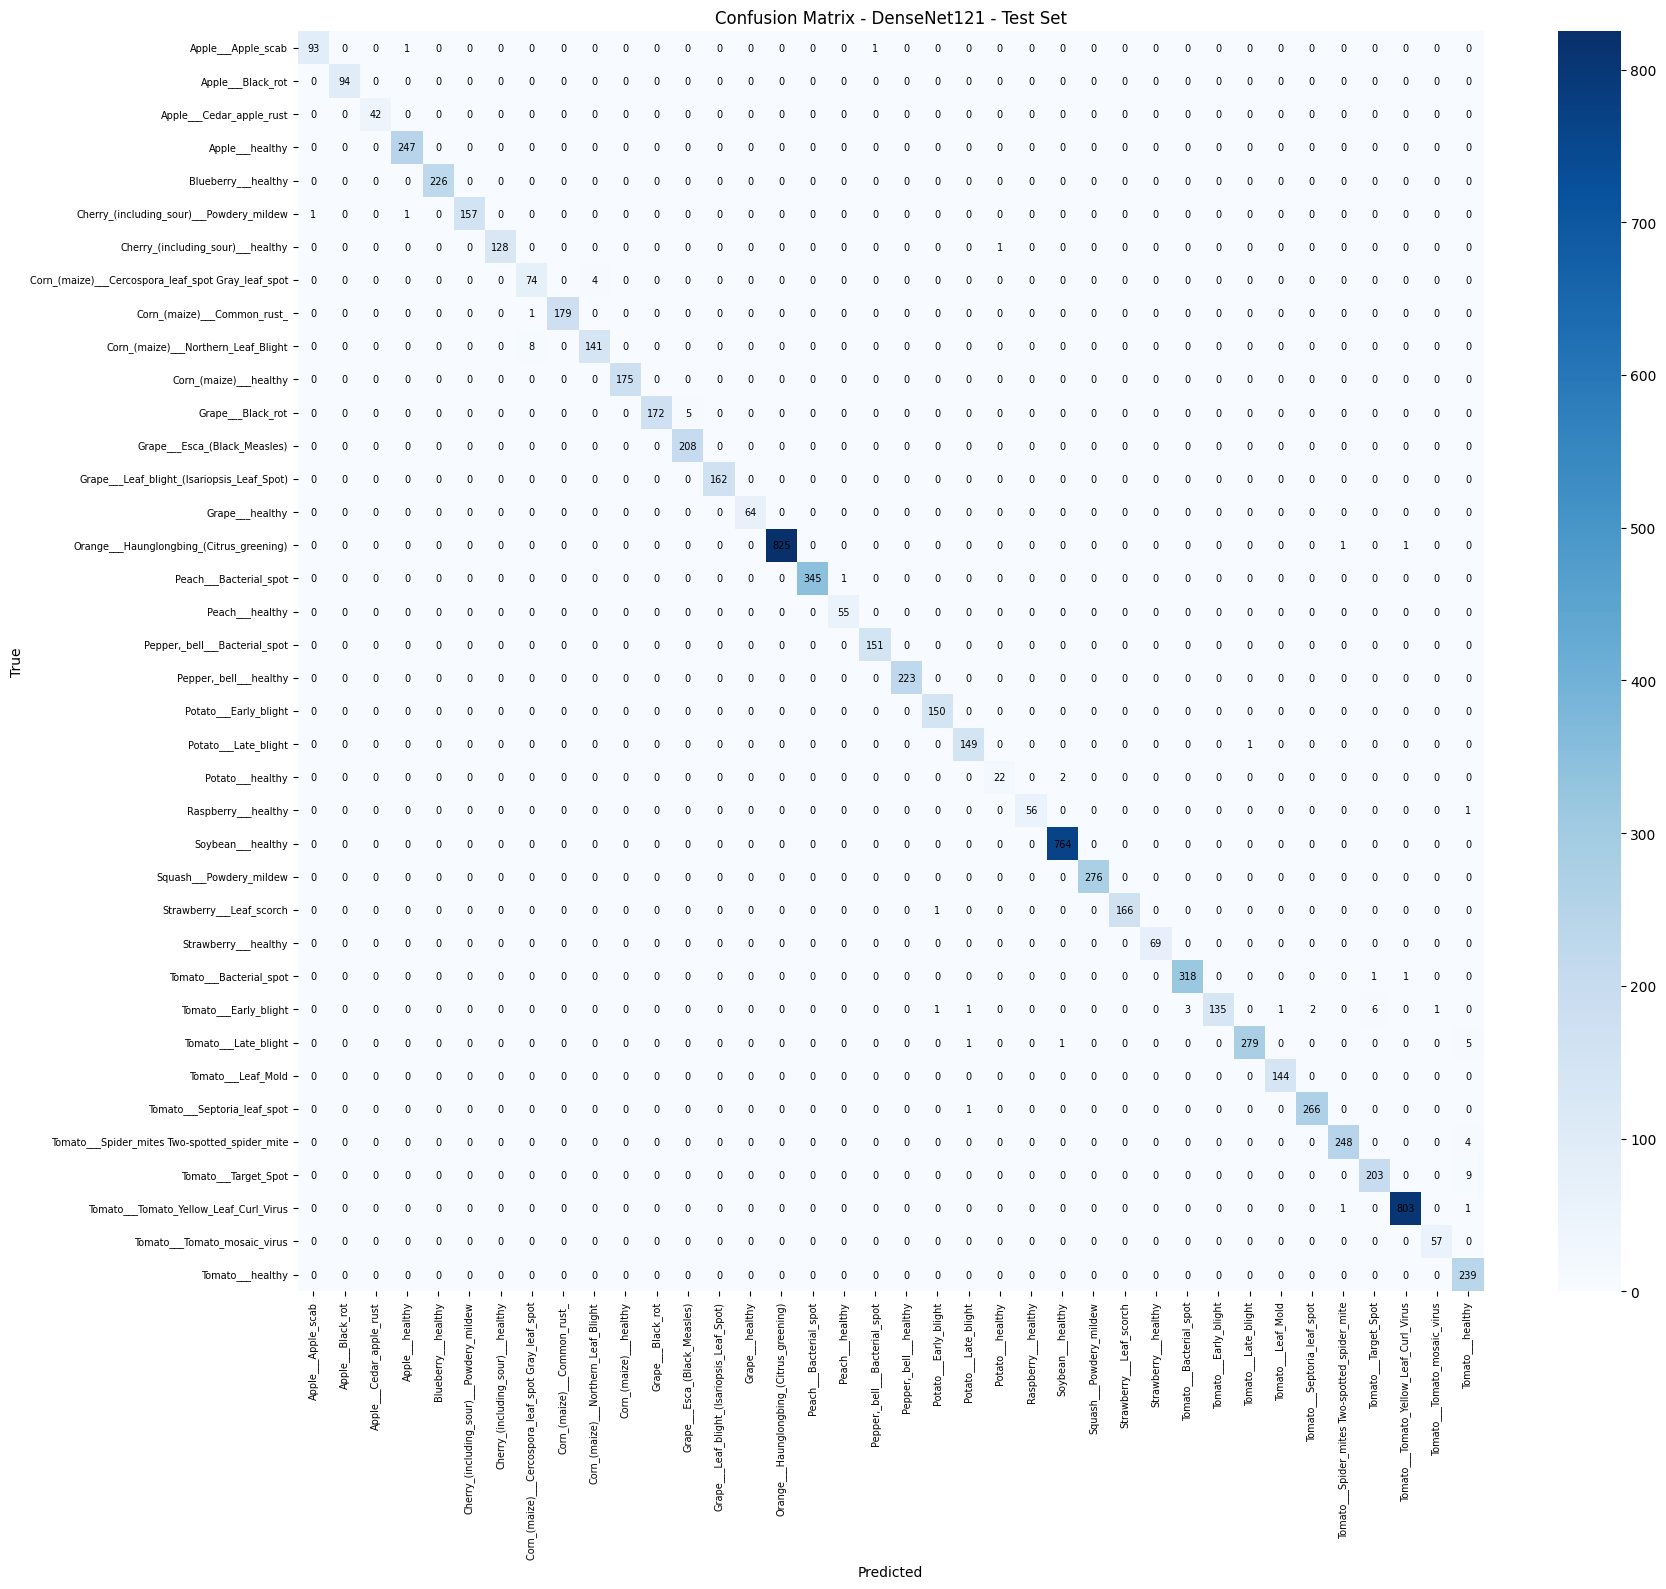

✅ DenseNet121 confusion matrix saved.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 16))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={
        "color": "black",
        "fontsize": 7
    }
)

plt.title(
    "Confusion Matrix - DenseNet121 - Test Set"
)

plt.xlabel("Predicted")

plt.ylabel("True")

plt.xticks(
    rotation=90,
    fontsize=7
)

plt.yticks(
    rotation=0,
    fontsize=7
)

plt.tight_layout()

plt.savefig(
    "/content/confusion_matrix_densenet121.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

plt.close()

print("✅ DenseNet121 confusion matrix saved.")

In [ ]:
import os
import json

# Folder for final DenseNet121 results
results_dir = (
    "/content/drive/MyDrive/"
    "DenseNet121_Final_Results"
)

os.makedirs(
    results_dir,
    exist_ok=True
)

# Save classification report
report_path = os.path.join(
    results_dir,
    "classification_report_densenet121.txt"
)

with open(report_path, "w") as f:
    f.write(report)

# Save confusion matrix
cm_path = os.path.join(
    results_dir,
    "confusion_matrix_densenet121.png"
)

import shutil

shutil.copy(
    "/content/confusion_matrix_densenet121.png",
    cm_path
)

# Save final metrics
metrics = {
    "model": "DenseNet121",
    "test_accuracy": float(exact_accuracy),
    "test_accuracy_percent": float(
        exact_accuracy * 100
    ),
    "test_loss": float(test_loss),
    "total_test_samples": int(len(y_true)),
    "correct_predictions": int(correct),
    "incorrect_predictions": int(incorrect),
    "num_classes": int(num_classes)
}

metrics_path = os.path.join(
    results_dir,
    "densenet121_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(
        metrics,
        f,
        indent=2
    )

print("✅ All DenseNet121 results saved.")
print("\nFolder:", results_dir)
print("\nFiles:")

for file in os.listdir(results_dir):
    print(" -", file)

print("\nFinal metrics:")
print(json.dumps(metrics, indent=2))

✅ All DenseNet121 results saved.

Folder: /content/drive/MyDrive/DenseNet121_Final_Results

Files:
 - classification_report_densenet121.txt
 - confusion_matrix_densenet121.png
 - densenet121_metrics.json

Final metrics:
{
  "model": "DenseNet121",
  "test_accuracy": 0.9913160469667319,
  "test_accuracy_percent": 99.1316046966732,
  "test_loss": 0.02609200030565262,
  "total_test_samples": 8176,
  "correct_predictions": 8105,
  "incorrect_predictions": 71,
  "num_classes": 38
}


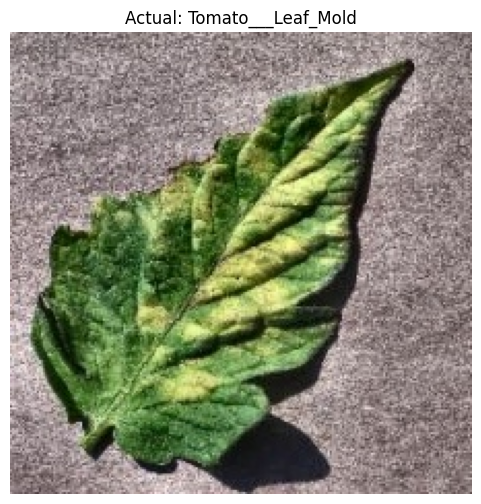

RANDOM DATASET IMAGE - DENSENET121

Image: 9afdf72c-5e19-40bd-8035-daf70f1cf8ce___Crnl_L.Mold 6617.JPG
Actual disease: Tomato___Leaf_Mold

Top 3 Predictions:
-----------------------------------------------------------------
1. Tomato___Leaf_Mold → 100.00%
2. Tomato___Septoria_leaf_spot → 0.00%
3. Tomato___Early_blight → 0.00%


In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Get all test image paths
all_test_paths = []

for class_name in class_names:

    class_dir = os.path.join(
        "/content/split_data/test",
        class_name
    )

    for filename in os.listdir(class_dir):

        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp")
        ):

            all_test_paths.append(
                (
                    os.path.join(class_dir, filename),
                    class_name
                )
            )

# Select a truly random image
image_path, actual_class = random.choice(
    all_test_paths
)

# Load image
image = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

image_array = tf.keras.utils.img_to_array(
    image
)

# Prepare image for prediction
input_image = tf.expand_dims(
    image_array,
    axis=0
)

input_image = (
    tf.keras.applications.densenet.preprocess_input(
        input_image
    )
)

# Predict
prediction = model.predict(
    input_image,
    verbose=0
)

# Top 3 predictions
top_3_indices = np.argsort(
    prediction[0]
)[-3:][::-1]

# Display image
plt.figure(figsize=(6, 6))

plt.imshow(
    image_array.astype("uint8")
)

plt.axis("off")

plt.title(
    f"Actual: {actual_class}"
)

plt.show()

# Results
print("=" * 65)
print("RANDOM DATASET IMAGE - DENSENET121")
print("=" * 65)

print(
    f"\nImage: {os.path.basename(image_path)}"
)

print(
    f"Actual disease: {actual_class}"
)

print("\nTop 3 Predictions:")
print("-" * 65)

for rank, index in enumerate(
    top_3_indices,
    start=1
):

    confidence = (
        prediction[0][index] * 100
    )

    print(
        f"{rank}. "
        f"{class_names[index]} "
        f"→ {confidence:.2f}%"
    )

print("=" * 65)